#  Weerakkody W W M B (IT25101776)
Data Cleaning, Duplicate Removal and Leakage Checking



## Part 1 - Install libraries

In [1]:
%pip -q install kagglehub opencv-python-headless scikit-image scikit-learn

## Part 2 - Imports and project folders

In [2]:
from pathlib import Path
import os, zipfile, shutil, hashlib, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE = Path('/content') if Path('/content').exists() else Path.cwd()
WORK = BASE / 'brain_tumor_preprocessing'
DATA_DIR = WORK / 'dataset'
RESULTS = WORK / 'results'
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

## Part 3 - Download the assigned dataset from KaggleHub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sartajbhuvaji/brain-tumor-classification-mri")

print("Path to dataset files:", path)

DATASET_ROOT = Path(path)
TRAIN_DIR = DATASET_ROOT / "Training"
TEST_DIR = DATASET_ROOT / "Testing"

assert TRAIN_DIR.exists(), f"Training folder not found inside: {DATASET_ROOT}"
assert TEST_DIR.exists(), f"Testing folder not found inside: {DATASET_ROOT}"

print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)


Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Path to dataset files: /kaggle/input/brain-tumor-classification-mri
Training folder: /kaggle/input/brain-tumor-classification-mri/Training
Testing folder : /kaggle/input/brain-tumor-classification-mri/Testing


## Part 4 - Create Training and Testing manifests

In [4]:
def make_manifest(root, split_name):
    rows = []
    for class_dir in sorted([p for p in root.iterdir() if p.is_dir()]):
        for p in sorted(class_dir.rglob('*')):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({
                    'split': split_name,
                    'class_name': class_dir.name,
                    'path': str(p)
                })
    return pd.DataFrame(rows)

train_raw = make_manifest(TRAIN_DIR, 'Training')
test_raw = make_manifest(TEST_DIR, 'Testing')

print('Raw Training images:', len(train_raw))
print('Raw Testing images :', len(test_raw))
display(pd.concat({
    'Training': train_raw['class_name'].value_counts().sort_index(),
    'Testing': test_raw['class_name'].value_counts().sort_index()
}, axis=1).fillna(0).astype(int))

Raw Training images: 2870
Raw Testing images : 394


,Training,Testing
class_name,,
glioma_tumor,826,100
meningioma_tumor,822,115
no_tumor,395,105
pituitary_tumor,827,74


## Part 5 - EDA BEFORE cleaning: class distribution

,images
class_name,
glioma_tumor,826
meningioma_tumor,822
no_tumor,395
pituitary_tumor,827


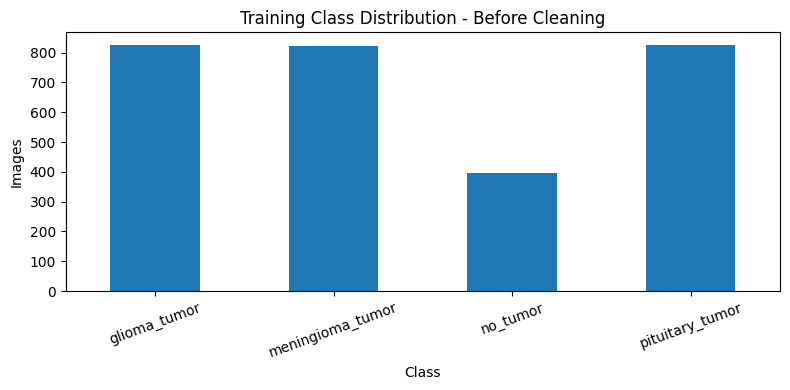

In [5]:
before_counts = train_raw['class_name'].value_counts().sort_index()
display(before_counts.to_frame('images'))
plt.figure(figsize=(8,4))
before_counts.plot(kind='bar')
plt.title('Training Class Distribution - Before Cleaning')
plt.xlabel('Class'); plt.ylabel('Images'); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

## Part 6 - Define corruption and exact-duplicate checking functions

In [6]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def image_is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def audit_manifest(df, label):
    out = df.copy()
    out['valid'] = out['path'].map(image_is_valid)
    out['sha256'] = None
    valid_idx = out.index[out['valid']].tolist()
    for n, idx in enumerate(valid_idx, start=1):
        out.at[idx, 'sha256'] = sha256_file(out.at[idx, 'path'])
        if n % 500 == 0:
            print(f'{label}: hashed {n}/{len(valid_idx)}')
    return out

## Part 7 - Run cleaning and Train/Test leakage checking

In [7]:
train_audit = audit_manifest(train_raw, 'Training')
test_audit = audit_manifest(test_raw, 'Testing')

train_valid = train_audit[train_audit['valid']].copy()
test_valid = test_audit[test_audit['valid']].copy()

# Exact duplicates inside Training: keep one copy.
train_valid['duplicate_in_training'] = train_valid.duplicated('sha256', keep='first')
duplicate_copies = train_valid[train_valid['duplicate_in_training']].copy()
train_unique = train_valid[~train_valid['duplicate_in_training']].copy()

# Exact Training <-> Testing overlap: keep official Test, remove Train copy.
test_hashes = set(test_valid['sha256'].dropna())
train_unique['overlaps_testing'] = train_unique['sha256'].isin(test_hashes)
cross_overlap = train_unique[train_unique['overlaps_testing']].copy()

train_clean = train_unique[~train_unique['overlaps_testing']].copy().reset_index(drop=True)
test_clean = test_valid.copy().reset_index(drop=True)

print('Raw Training                    :', len(train_raw))
print('Exact duplicate copies removed  :', len(duplicate_copies))
print('Unique Training after dedup      :', len(train_unique))
print('Unique Training/Test overlaps    :', len(cross_overlap))
print('Leakage-safe Training            :', len(train_clean))
print('Official Testing kept            :', len(test_clean))

Training: hashed 500/2870
Training: hashed 1000/2870
Training: hashed 1500/2870
Training: hashed 2000/2870
Training: hashed 2500/2870
Raw Training                    : 2870
Exact duplicate copies removed  : 93
Unique Training after dedup      : 2777
Unique Training/Test overlaps    : 64
Leakage-safe Training            : 2713
Official Testing kept            : 394


## Part 8 - EDA AFTER cleaning: before vs after and duplicate summary

,Before Cleaning,After Cleaning
class_name,,
glioma_tumor,826,818
meningioma_tumor,822,814
no_tumor,395,271
pituitary_tumor,827,810



Duplicate copies removed by class:


,duplicate_copies
class_name,
glioma_tumor,8
meningioma_tumor,8
no_tumor,60
pituitary_tumor,17



Exact Training/Test overlaps removed from Training:


,overlap_images
class_name,
no_tumor,64


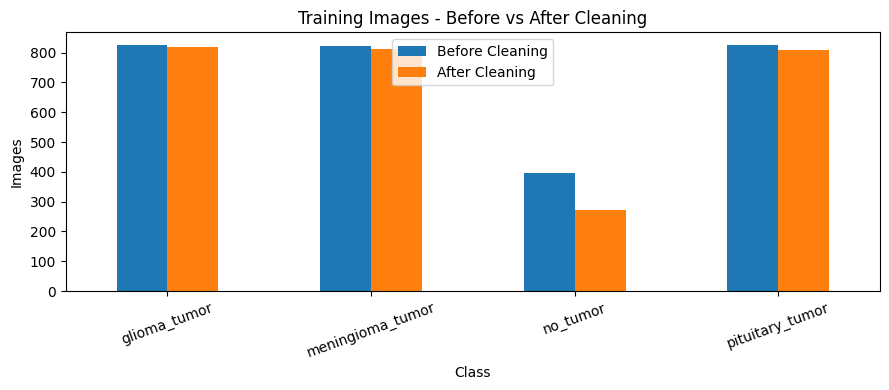

In [8]:
after_counts = train_clean['class_name'].value_counts().sort_index()
comparison = pd.concat([
    before_counts.rename('Before Cleaning'),
    after_counts.rename('After Cleaning')
], axis=1).fillna(0).astype(int)

display(comparison)
print('\nDuplicate copies removed by class:')
display(duplicate_copies['class_name'].value_counts().sort_index().to_frame('duplicate_copies'))
print('\nExact Training/Test overlaps removed from Training:')
display(cross_overlap['class_name'].value_counts().sort_index().to_frame('overlap_images'))

comparison.plot(kind='bar', figsize=(9,4))
plt.title('Training Images - Before vs After Cleaning')
plt.xlabel('Class'); plt.ylabel('Images'); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

## Part 9 - Save reports and cleaned dataset

In [9]:
OUT = RESULTS / 'member1_cleaning'
CLEAN_ROOT = OUT / 'cleaned_dataset'
OUT.mkdir(parents=True, exist_ok=True)

train_audit.to_csv(OUT/'training_audit.csv', index=False)
test_audit.to_csv(OUT/'testing_audit.csv', index=False)
duplicate_copies.to_csv(OUT/'training_duplicate_copies.csv', index=False)
cross_overlap.to_csv(OUT/'training_testing_overlap.csv', index=False)
train_clean.to_csv(OUT/'clean_training_manifest.csv', index=False)
test_clean.to_csv(OUT/'official_testing_manifest.csv', index=False)

for df, split in [(train_clean,'Training'), (test_clean,'Testing')]:
    for row in df.itertuples(index=False):
        src = Path(row.path)
        dst_dir = CLEAN_ROOT / split / row.class_name
        dst_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst_dir/src.name)
print('Saved:', OUT)

Saved: /content/brain_tumor_preprocessing/results/member1_cleaning


## Part 10 - Download Member 1 outputs

In [10]:
def make_zip(folder, zip_path):
    folder = Path(folder)
    zip_path = Path(zip_path)
    if zip_path.exists():
        zip_path.unlink()
    shutil.make_archive(str(zip_path.with_suffix('')), 'zip', root_dir=folder)
    return zip_path

def download_file(path):
    try:
        from google.colab import files
        files.download(str(path))
    except Exception:
        print('Saved at:', path)

In [11]:
ZIP_OUT = make_zip(OUT, RESULTS/'Member1_Cleaning_Outputs.zip')
print('Created:', ZIP_OUT)
download_file(ZIP_OUT)

Created: /content/brain_tumor_preprocessing/results/Member1_Cleaning_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>